In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,ConfusionMatrixDisplay)

In [ ]:
df=pd.read_csv("/content/drive/MyDrive/datasets/customer_churn_dataset.csv")

In [ ]:
df.describe()

,age,tenure_months,monthly_charges,contract_type,payment_method,num_support_calls,internet_service,num_services,late_payments,churn
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,43.951417,36.521583,70.540333,0.661333,1.502667,2.070500,1.143083,3.495917,0.950917,0.373000
std,15.271673,20.950404,28.959980,0.798973,1.114718,1.935719,0.728689,1.697220,1.242767,0.483622
min,18.000000,1.000000,20.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,31.000000,18.000000,46.000000,0.000000,1.000000,0.000000,1.000000,2.000000,0.000000,0.000000
50%,44.000000,37.000000,71.000000,0.000000,2.000000,2.000000,1.000000,3.000000,1.000000,0.000000
75%,57.000000,55.000000,96.000000,1.000000,2.000000,3.000000,2.000000,5.000000,1.000000,1.000000
max,70.000000,72.000000,120.000000,2.000000,3.000000,8.000000,2.000000,6.000000,5.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   age                12000 non-null  int64
 1   tenure_months      12000 non-null  int64
 2   monthly_charges    12000 non-null  int64
 3   contract_type      12000 non-null  int64
 4   payment_method     12000 non-null  int64
 5   num_support_calls  12000 non-null  int64
 6   internet_service   12000 non-null  int64
 7   num_services       12000 non-null  int64
 8   late_payments      12000 non-null  int64
 9   churn              12000 non-null  int64
dtypes: int64(10)
memory usage: 937.6 KB


In [ ]:
df.isnull().sum()

,0
age,0
tenure_months,0
monthly_charges,0
contract_type,0
payment_method,0
num_support_calls,0
internet_service,0
num_services,0
late_payments,0
churn,0


In [ ]:
df.duplicated().sum()

np.int64(0)

churn
0    7524
1    4476
Name: count, dtype: int64

churn rate:37.3%


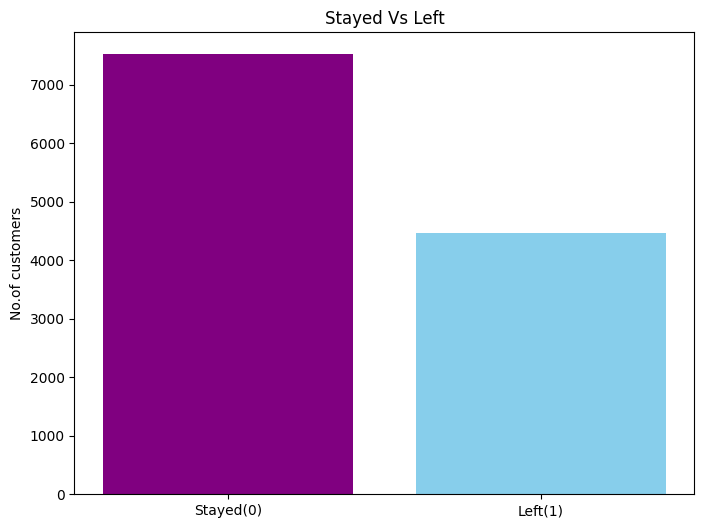

In [ ]:
counts=df.churn.value_counts().sort_index()
print(counts)
print(f"\nchurn rate:{df['churn'].mean()*100:.1f}%")
plt.figure(figsize=(8,6))
plt.bar(['Stayed(0)','Left(1)'],counts.values,color=["purple","skyblue"])
plt.ylabel("No.of customers")
plt.title("Stayed Vs Left")
plt.show()

In [ ]:
df.corr()["churn"].sort_values(ascending=False)

,churn
churn,1.000000
monthly_charges,0.186145
num_support_calls,0.184497
late_payments,0.108253
internet_service,0.053105
payment_method,-0.042039
age,-0.047354
num_services,-0.085463
tenure_months,-0.263349
contract_type,-0.290122


In [ ]:
df.groupby('contract_type')["churn"].mean().mul(100).round(1).rename('Churn rate %')

,Churn rate %
contract_type,
0,49.3
1,29.7
2,14.8


In [ ]:
X=df.drop('churn',axis=1)
y=df["churn"]
print(X.shape)
print(y.shape)

(12000, 9)
(12000,)


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=45,stratify=y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(9600, 9)
(2400, 9)
(9600,)
(2400,)


In [ ]:
model=RandomForestClassifier(n_estimators=200,max_depth=8,min_samples_leaf=5,random_state=45,n_jobs=-1)
model.fit(X_train,y_train)
print("no.of trees in the forest",len(model.estimators_))

no.of trees in the forest 200


In [ ]:
y_pred=model.predict(X_test)
y_prob=model.predict_proba(X_test)[:,1]
comparison=pd.DataFrame({
    "Actual":y_test.values[:10],
    "Predicted":y_pred[:10]})
comparison

,Actual,Predicted
0,1,1
1,0,0
2,1,1
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,0,1
9,0,0


In [ ]:
acc=accuracy_score(y_test,y_pred)
prec=precision_score(y_test,y_pred)
recall=recall_score(y_test,y_pred)
f1=f1_score(y_test,y_pred)

print(f"Accuracy:{acc:.3f}")
print(f"Precision:{prec:.3f}")
print(f"Recall:{recall:.3f}")
print(f"f1:{f1:.3f}")

Accuracy:0.724
Precision:0.666
Recall:0.522
f1:0.585


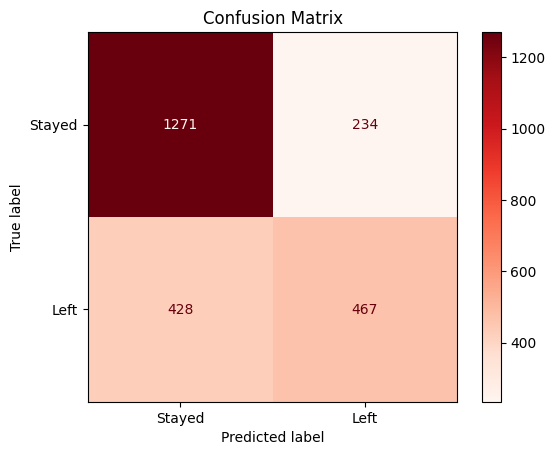

              precision    recall  f1-score   support

      Stayed       0.75      0.84      0.79      1505
        Left       0.67      0.52      0.59       895

    accuracy                           0.72      2400
   macro avg       0.71      0.68      0.69      2400
weighted avg       0.72      0.72      0.72      2400



In [ ]:
cm=confusion_matrix(y_test,y_pred)
ConfusionMatrixDisplay(cm,display_labels=['Stayed','Left']).plot(cmap="Reds")
plt.title('Confusion Matrix')
plt.show()
print(classification_report(y_test,y_pred,target_names=["Stayed","Left"]))

In [ ]:
tree=DecisionTreeClassifier(max_depth=8,min_samples_leaf=5,random_state=45)
tree.fit(X_train,y_train)
tree_pred=tree.predict(X_test)
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, tree_pred), acc],
    'Precision': [precision_score(y_test, tree_pred), prec],
    'Recall': [recall_score(y_test, tree_pred), recall],
    'F1': [f1_score(y_test, tree_pred), f1]
}).round(3)

results

,Model,Accuracy,Precision,Recall,F1
0,Decision Tree,0.707,0.624,0.539,0.578
1,Random Forest,0.724,0.666,0.522,0.585


In [ ]:
importance=pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance.round(3))

tenure_months        0.270
contract_type        0.242
monthly_charges      0.165
num_support_calls    0.131
age                  0.060
late_payments        0.045
num_services         0.040
internet_service     0.024
payment_method       0.023
dtype: float64


In [ ]:
new_customer = pd.DataFrame([{
    'age': 29,
    'tenure_months': 4,
    'monthly_charges': 95,
    'contract_type': 0,
    'payment_method': 0,
    'num_support_calls': 5,
    'internet_service': 2,
    'num_services': 2,
    'late_payments': 3
}])

label = model.predict(new_customer)[0]
prob = model.predict_proba(new_customer)[0, 1]

print('Prediction :','WILL LEAVE' if label == 1 else 'WILL STAY')

Prediction : WILL LEAVE


In [ ]:
import joblib
joblib.dump(model,"customer_model.pkl")

['customer_model.pkl']

In [ ]:
from google.colab import files
files.download("customer_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>